# Retention analysis, step by step

This notebook walks through the pipeline in `src/retention/` one step at a time. It does no analysis of its own: every
cell calls a function from the package and shows what came out, so you can see what each step does to the data.

**The questions**
1. How do we measure whether a user is engaged and retained?
2. How does retention look by cohort, and where do we lose people?
3. Which users are likely to stop paying, early enough to act?
4. Who should the retention team contact, given what an offer costs?

**The route**

| Part | What happens | Code |
|---|---|---|
| 0 | Look at the four raw files | |
| 1 | Monthly table → active flag → cohort retention and engagement | `data.py`, `cohorts.py` |
| 2 | Raw transactions and daily app use → weekly snapshots with features and a churn label | `daily.py` |
| 3 | Split by time, with a gap so no future outcome leaks into training | `model.py` |
| 4 | Rule baseline, logistic regression, gradient boosting → metrics, lift, threshold | `model.py` |
| 5 | Backtest the same thing on several 4-week windows | `model.py` |

Running the whole notebook takes a few minutes: it reads about 2.3 GB of CSVs.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebook":
    os.chdir("..")  # data paths in Settings are relative to the project root

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from retention import cohorts, daily, data, model
from retention.config import Settings

settings = Settings()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)


def peek(df, n=5):
    """Show the first rows with the long hashed user ids cut short, so the table fits."""
    out = df.head(n).copy()
    for col in ("user", "user_id", "u"):
        if col in out:
            out[col] = out[col].astype(str).str[:12] + "…"
    return out


settings

Settings(columns=Columns(user='user_id', year='Year', month='Month', chats='chat_conversations', opens='app_opens', searches='app_searches', card='mastercard', p2p='p2p_payment', age='age', friends='friends_on_monzo', android_pay='android_pay_activated', photo='profile_photo_upload', overdraft='offered_overdraft'), input='daily', core_path='data/df_core.csv', transactions_path='data/df_transactions.csv', daily_path='data/df_users_activity_daily.csv', users_path='data/df_users.csv', reports_dir='reports', label_months=2, label_days=60, lookback_days=60, min_p2p_amount=1.0, test_window_days=28, min_history_months=2, last_complete_month='2018-05', backtest_min_train_rows=2000, min_active_users=200, top_share=0.1, offer_cost=20.0, offer_success_rate=0.2, customer_value=300.0, random_state=0)

## 0. The raw data

There are four files in `data/`:

- **core**: one row per user per month, already aggregated. `mastercard` and `p2p_payment` are the *mean* amount per
  transaction that month, not totals. This is the fallback input.
- **transactions**: one row per payment, with a timestamp, the type (`mastercard` or `p2p_payment`) and the amount
  (negative means money out).
- **daily activity**: one row per user per day with app opens, searches and support chats.
- **users**: one row per user with age, number of friends on the app, and the dates of a few one-off events.

In [2]:
files = {
    "core (monthly)": settings.core_path,
    "transactions": settings.transactions_path,
    "daily activity": settings.daily_path,
    "users": settings.users_path,
}
for name, path in files.items():
    print(f"--- {name}: {path}")
    display(peek(pd.read_csv(path, nrows=5)))

--- core (monthly): data/df_core.csv


--- transactions: data/df_transactions.csv


--- daily activity: data/df_users_activity_daily.csv


--- users: data/df_users.csv


## 1. Monthly view: who is active, and how cohorts retain

### 1a. Load the monthly table and define "active"

`data.load_core` keeps the columns we need, gives them short names, turns year and month into one `month` column and
adds the key definition of the project:

> **A user is active in a month if they made a payment (card or p2p).** Opening the app does not count: that is
> usage, not value.

In [3]:
core = data.load_core(settings)
print(f"{len(core):,} user-months, {core['user'].nunique():,} users")
peek(core)

2,590,452 user-months, 71,957 users


### 1b. Keep only the months we can trust

`data.restrict_to_observed` drops users who never paid, and for everyone else keeps the months from their first payment
up to the last complete month (June 2018 is partial).

In [4]:
df = data.restrict_to_observed(core, settings)
print(f"Before: {len(core):,} rows, {core['user'].nunique():,} users")
print(f"After:  {len(df):,} rows, {df['user'].nunique():,} users who paid at least once")

# One user's history, to see what a row means
example = df.groupby("user").size().idxmax()
peek(df[df["user"] == example], n=12)

Before: 2,590,452 rows, 71,957 users
After:  159,556 rows, 51,612 users who paid at least once


### 1c. Retention by cohort

Users are grouped by the month of their first payment (the **cohort**) and followed month by month. Each cell is the
share of the cohort that paid in that month after joining. Months we have not seen yet are blank, not 0%, so late
cohorts are not counted as lost before they had the chance to stay.

Read across a row to see how one cohort fades. Read down a column to compare cohorts at the same age.

In [5]:
matrix = cohorts.retention_matrix(df)
rates = matrix.columns.drop("cohort_size")
matrix.style.format("{:.0%}", subset=rates, na_rep="").background_gradient(cmap="Greens", subset=rates, vmin=0, vmax=1)

tenure,cohort_size,0,1,2,3,4,5,6,7,8,9,10,11
cohort,,,,,,,,,,,,,
2017-06,11,100%,27%,27%,9%,9%,9%,9%,9%,9%,9%,9%,9%
2017-07,2,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,
2017-10,2,100%,50%,50%,50%,50%,50%,50%,50%,,,,
2017-11,260,100%,90%,84%,80%,81%,78%,78%,,,,,
2017-12,3825,100%,92%,85%,84%,83%,82%,,,,,,
2018-01,7506,100%,92%,87%,83%,82%,,,,,,,
2018-02,8743,100%,89%,82%,80%,,,,,,,,
2018-03,10414,100%,88%,82%,,,,,,,,,
2018-04,10023,100%,87%,,,,,,,,,,


### 1d. Engagement per active user, by tenure

Averages over everyone would move just because the user base grew fast (lots of brand new users). So we compare users
at the same tenure (months since first payment), counting only those active that month.

Tenures with fewer than 200 active users are left out (`min_active_users`). Only a handful of users from mid-2017 reach
tenure 7 or more, and a few heavy early users (testers, staff) would make the averages jump.

,active_users,opens_per_user,searches_per_user,chats_per_user,share_using_p2p,median_card_amount,chats_per_100_opens
tenure,,,,,,,
0,51612,39.13,0.26,0.10,0.22,-11.16,0.26
1,36264,50.30,0.29,0.09,0.29,-10.55,0.18
2,25692,47.44,0.25,0.08,0.34,-10.54,0.17
3,16668,48.19,0.27,0.08,0.37,-10.57,0.17
4,9567,49.86,0.30,0.09,0.39,-10.57,0.18
5,3353,52.16,0.34,0.08,0.39,-10.52,0.16
6,206,49.43,0.46,0.12,0.47,-10.26,0.24


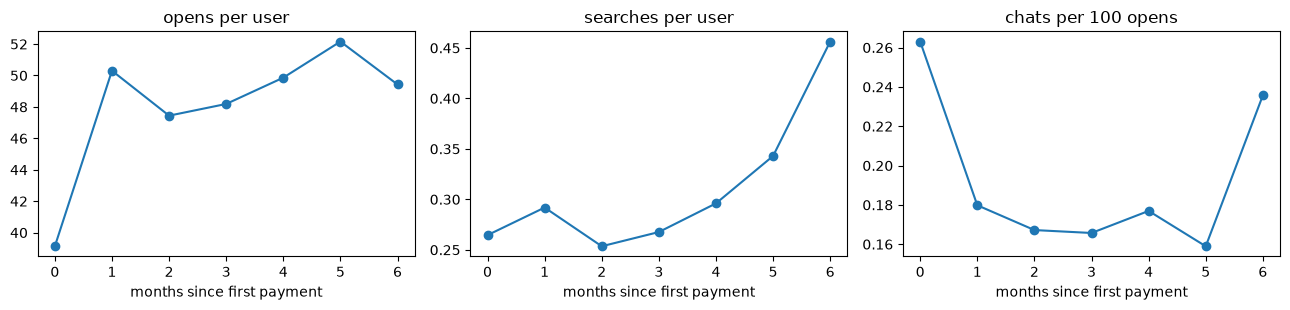

In [6]:
engagement = cohorts.engagement_by_tenure(df, settings.min_active_users)
display(engagement.round(2))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, col in zip(axes, ["opens_per_user", "searches_per_user", "chats_per_100_opens"]):
    engagement[col].plot(ax=ax, marker="o", title=col.replace("_", " "))
    ax.set_xlabel("months since first payment")
plt.tight_layout()

### 1e. Do users who contact support leave more?

Churn here means no payment in the next 2 months. A quick look at churn rate by number of support chats in the month.
This is a correlation, not a cause.

In [7]:
cohorts.chats_and_churn(df, settings.label_months)

,churn_rate,user_months
chats,,
0,0.060253,58586
1,0.068777,3475
2-3,0.069767,645
4+,0.197674,86


## 2. Daily view: building the table the model learns from

The monthly table hides a lot: amounts are averages, there is no count of payments, and a month is a coarse clock. So
for the model we go back to the raw transactions and daily app use.

The idea is a **snapshot**: stand on a Monday, look only backwards to describe the user (features), then look forwards
60 days to see whether they paid again (label). We repeat this every Monday.

### 2a. Load the raw tables into DuckDB

The files are large (1.2 GB of transactions), so `daily.load` reads them with DuckDB and builds a few intermediate
tables. It also prints what the payment rules removed:

- **card**: only spends count as payments. Refunds (positive amounts) and zero amounts are not payments.
- **p2p**: transfers under £1 in either direction are treated as test transfers (there are thousands of exactly ±£0.01).

In [8]:
con = daily.load(settings)
con.execute("SET enable_progress_bar = false")

def q(sql):
    return con.sql(sql).df()

q("""
    SELECT 'raw (all transactions)' AS step, count(*) AS rows FROM raw
    UNION ALL SELECT 'pay (payments only)', count(*) FROM pay
    UNION ALL SELECT 'act (daily app use)', count(*) FROM act
""")

p2p rows removed (|amount| < 1.0): 8,757 of 186,381
card rows removed (refunds or zero): 90,573 of 4,772,581


,step,rows
0,raw (all transactions),4958962
1,pay (payments only),4859632
2,act (daily app use),2198093


What a removed p2p "test transfer" looks like, and what kinds of payment are left:

In [9]:
display(peek(q("SELECT * FROM raw WHERE payment_type = 'p2p_payment' AND abs(amount) < 1 LIMIT 5")))
q("""
    SELECT kind, count(*) AS payments, count(DISTINCT u) AS users,
           round(median(amount), 2) AS median_amount
    FROM pay GROUP BY kind ORDER BY payments DESC
""")

,kind,payments,users,median_amount
0,card,4682008,57095,-6.78
1,p2p_out,89834,18355,-12.50
2,p2p_in,87790,18116,12.50


### 2b. Pick the snapshot dates and who gets scored

Snapshots are Mondays at 00:00. The first one is 60 days after the data starts (so there is history to look back on),
the last one is 60 days before the data ends (so the label window is complete).

On each Monday we score only users who **paid in the 60 days before**. Someone who already left months ago is not a
churn risk anymore, they are already gone.

37 Mondays, from 2017-08-07 to 2018-04-16


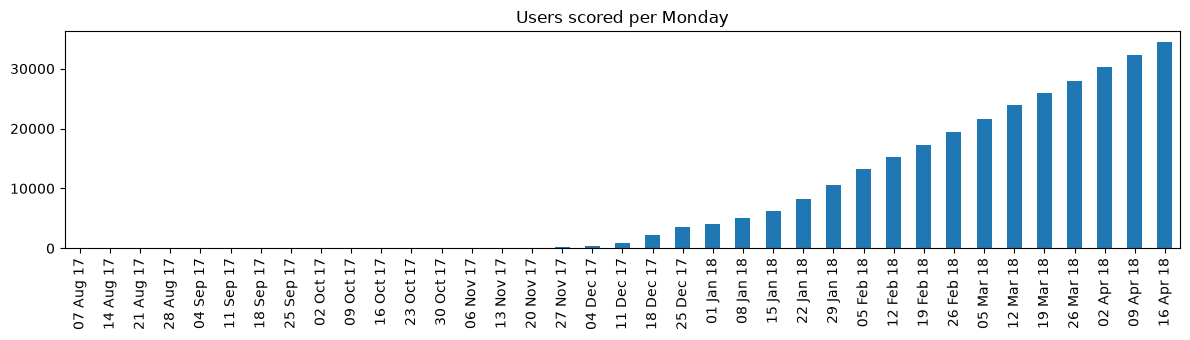

In [10]:
per_week = q("SELECT snap, count(*) AS users_scored FROM snaps GROUP BY snap ORDER BY snap")
print(f"{len(per_week)} Mondays, from {per_week.snap.min().date()} to {per_week.snap.max().date()}")

ax = per_week.set_index(per_week.snap.dt.strftime("%d %b %y")).users_scored.plot.bar(
    figsize=(12, 3.5), title="Users scored per Monday")
ax.set_xlabel("")
plt.tight_layout()

The user base grows fast from late 2017. Early Mondays have only a handful of users, which matters later for how much
training data the early test windows have.

### 2c. Turn each (user, Monday) into one row of features and a label

`daily.snapshot_features` aggregates, for each user and Monday:

| Feature | Looks at |
|---|---|
| days since last payment, days since last app open | everything before the Monday (app open capped at 90 days) |
| payment count, card spend, p2p out, p2p in | last 30 days |
| active payment days | last 30 and 90 days |
| opens in the last 7 days, and their trend vs the 21 days before | last 28 days |
| searches, chats, chats per 100 opens | last 30 days |
| age, friends, android pay / photo set up before the Monday | users table |

and the **label**: `churn = 1` if the user makes no payment in the 60 days from the Monday.

In [11]:
snaps = daily.snapshot_features(con, settings)
print(f"{len(snaps):,} rows = (user, Monday) pairs, churn rate {snaps.churn.mean():.1%}")
peek(snaps)

303,354 rows = (user, Monday) pairs, churn rate 8.3%


### 2d. One user, one snapshot, made visible

Here is what a single row means. Dots are payments. Everything left of the dashed line feeds the features, everything in
the shaded area decides the label. The model never sees the shaded area when it makes a prediction.

The leaver is shown at the **first Monday after their last payment**: the first snapshot with `churn = 1`. On the Mondays
before it, a later payment still falls inside the 60-day window, so those snapshots are labelled `churn = 0`.

In [12]:
def show_snapshot(row):
    s = row.snap.to_pydatetime()
    pays = con.execute(
        """SELECT ts, kind, amount FROM pay
           WHERE u = ? AND ts >= ? - INTERVAL 90 DAY AND ts < ? + INTERVAL 60 DAY ORDER BY ts""",
        [row.user, s, s],
    ).df()
    fig, ax = plt.subplots(figsize=(12, 2.4))
    for kind, group in pays.groupby("kind"):
        ax.scatter(group.ts, np.zeros(len(group)) + {"card": 0, "p2p_out": 0.3, "p2p_in": -0.3}[kind], label=kind, s=18)
    ax.axvline(row.snap, color="k", ls="--")
    ax.axvspan(row.snap, row.label_end, color="tab:orange", alpha=0.12, label="label window (60 days)")
    ax.set_yticks([])
    ax.set_xlim(row.snap - pd.Timedelta(days=90), row.label_end)
    ax.set_title(f"snapshot {row.snap.date()}  →  churn = {row.churn}")
    ax.legend(loc="upper left", fontsize=8, ncol=4)
    plt.show()
    display(row[daily.FEATURES + ["churn"]].to_frame("value").T)


monday = snaps.snap.sort_values().unique()[-6]
stayer = snaps[(snaps.snap == monday) & (snaps.churn == 0) & (snaps.pay_count_30d.between(5, 30))].iloc[0]
# A leaver at the first Monday after their last payment: the first snapshot labelled churn = 1
ordered = snaps.sort_values(["user", "snap"])
first_churn = ordered[(ordered.churn == 1) & (ordered.groupby("user").churn.shift(1) == 0)]
leaver = first_churn[(first_churn.snap == monday) & (first_churn.pay_count_30d >= 5)].iloc[0]
show_snapshot(stayer)
show_snapshot(leaver)

### 2e. Do the features separate leavers from stayers?

Median of each feature for users who stayed (0) and users who left (1). If a feature differs a lot between the two
columns, it is likely to help the model.

In [13]:
snaps.groupby("churn")[daily.FEATURES].median().T.round(1)

churn,0,1
days_since_last_payment,1.4,17.9
days_since_last_open,2.0,9.0
pay_count_30d,18.0,2.0
card_spend_30d,210.7,15.0
p2p_out_30d,0.0,0.0
p2p_in_30d,0.0,0.0
active_days_30,9.0,1.0
active_days_90,13.0,5.0
opens_7d,8.0,0.0
opens_trend,0.0,-0.1


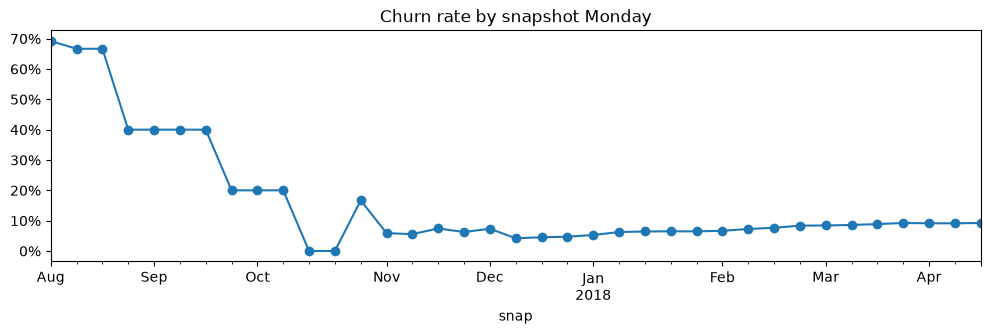

In [14]:
ax = snaps.groupby("snap").churn.mean().plot(figsize=(12, 3), marker="o", title="Churn rate by snapshot Monday")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"));

## 3. Split by time, with a gap

A random split would let the model train on rows from the same weeks it is tested on, and worse, train on labels that
were not known yet at test time. Instead:

- **test** = the snapshots in the last 4 weeks
- **train** = only snapshots whose 60-day label window had *ended* before the test window starts
- the snapshots in between are not used: their outcome was not known yet when the test window starts (the **gap**)

train: 30,816 rows, snapshots up to 2018-01-22 (their labels end by 2018-03-23)
test:  125,156 rows, snapshots 2018-03-26 to 2018-04-16


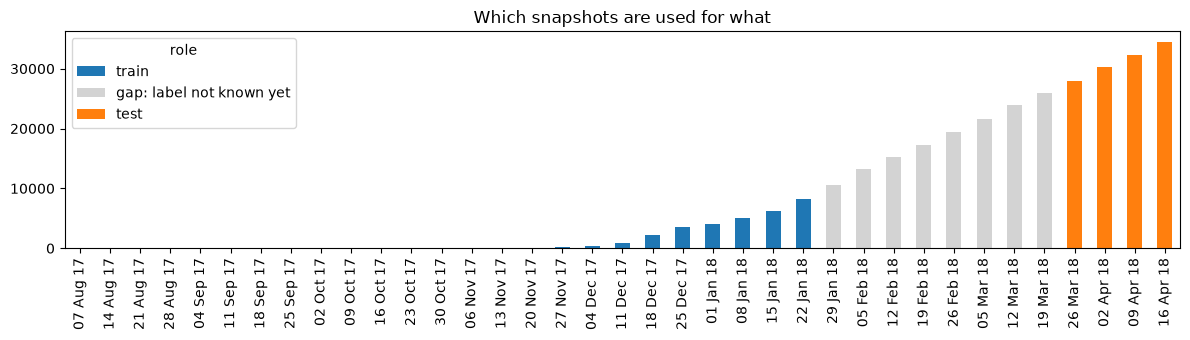

In [15]:
split = model.time_split(snaps, settings)
role = np.where(
    snaps.snap >= split.test_start, "test",
    np.where(snaps.label_end <= split.test_start, "train", "gap: label not known yet"),
)
counts = snaps.assign(role=role).groupby(["snap", "role"]).size().unstack(fill_value=0)
counts = counts[["train", "gap: label not known yet", "test"]]
counts.index = counts.index.strftime("%d %b %y")

print(f"train: {len(split.train):,} rows, snapshots up to {split.train.snap.max().date()} "
      f"(their labels end by {split.train.label_end.max().date()})")
print(f"test:  {len(split.test):,} rows, snapshots {split.test_start.date()} to {split.test_end.date()}")

ax = counts.plot.bar(stacked=True, figsize=(12, 3.5), color=["tab:blue", "lightgrey", "tab:orange"],
                     title="Which snapshots are used for what")
ax.set_xlabel("")
plt.tight_layout()

The test set is much bigger than the training set because the user base grew so fast. That is the honest situation a
team would be in when deploying the model in April 2018.

## 4. Baseline first, then models

Three ways to rank users by risk:

- **rule baseline**: no model, just "the longer since the last payment, the higher the risk". This is the bar to beat.
- **logistic regression**: a linear model (missing values filled with the median, features standardised).
- **gradient boosting**: trees, can pick up non-linear patterns.

How we judge them:

- **PR-AUC**: how well the ranking puts leavers at the top, with churn being the minority class.
- **ROC-AUC**: the chance a random leaver is ranked above a random stayer.
- **recall / precision in the top 10%**: if the team can only call 10% of users, how many leavers do they reach, and how
  many of the calls are to real leavers.
- **lift in the top 10%**: precision divided by the base churn rate. A lift of 4 means the list is 4x richer in leavers
  than calling at random.
- **Brier**: how close the probabilities are to what happens (lower is better), which matters for the money threshold.

In [16]:
results = model.run(snaps, settings)
print(f"best model by PR-AUC: {results['best_model']}, test churn rate {results['churn_rate_test']:.1%}")
pd.DataFrame(results["models"]).T.round(3)

best model by PR-AUC: logistic, test churn rate 9.2%


,pr_auc,roc_auc,recall_top_10pct,precision_top_10pct,lift_top_10pct,brier,expected_gain
rule_baseline,0.375,0.863,0.446,0.410,4.463,NaN,NaN
logistic,0.396,0.871,0.456,0.419,4.563,0.072,62180.0
gradient_boosting,0.369,0.871,0.437,0.402,4.375,0.071,50720.0


### 4a. What "lift" looks like

Sort the test users by the best model's score and cut them into 10 equal groups. The first group is the 10% the model
is most worried about.

,users,churn_rate,mean_p
decile,,,
1,12516,41.9%,64.4%
2,12516,23.1%,21.3%
3,12515,12.1%,9.2%
4,12516,6.3%,5.4%
5,12515,3.8%,3.5%
6,12516,2.0%,2.2%
7,12515,1.3%,1.3%
8,12516,0.6%,0.8%
9,12515,0.4%,0.4%


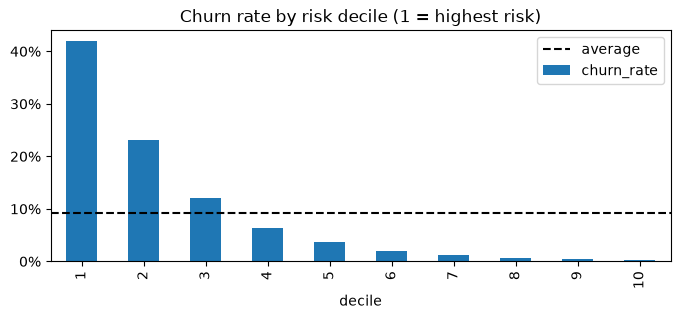

In [17]:
best = results["_fitted"]
test = split.test.assign(p=best.predict_proba(split.test[model.feature_columns(split.test)])[:, 1])
test["decile"] = pd.qcut(test.p.rank(method="first", ascending=False), 10, labels=range(1, 11))
by_decile = test.groupby("decile", observed=True).agg(users=("churn", "size"), churn_rate=("churn", "mean"),
                                                      mean_p=("p", "mean"))
display(by_decile.style.format({"churn_rate": "{:.1%}", "mean_p": "{:.1%}"}))

ax = by_decile.churn_rate.plot.bar(figsize=(8, 3), title="Churn rate by risk decile (1 = highest risk)")
ax.axhline(test.churn.mean(), color="k", ls="--", label="average")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend()
plt.show()

### 4b. Who to contact: a threshold from money, not 0.5

Contacting a user costs an offer. It pays off when

> probability of churn × chance the offer works × customer value > offer cost

With the placeholder numbers in `config.py` (cost 20, success 20%, value 300) the break-even probability is 33%.
These inputs belong to the business, not to the model.

In [18]:
be = model.break_even_probability(settings)
contact = test[test.p >= be]
print(f"break-even probability: {be:.0%}")
print(f"users above it: {len(contact):,} of {len(test):,} ({len(contact) / len(test):.1%})")
print(f"churn rate among them: {contact.churn.mean():.1%} (vs {test.churn.mean():.1%} overall)")
print(f"expected gain on the test window: {results['models'][results['best_model']]['expected_gain']:,.0f}")

break-even probability: 33%
users above it: 13,025 of 125,156 (10.4%)
churn rate among them: 41.3% (vs 9.2% overall)
expected gain on the test window: 62,180


### 4c. What drives the predictions

Permutation importance: shuffle one feature at a time on the test set and see how much PR-AUC drops. A big drop means
the model leans on that feature.

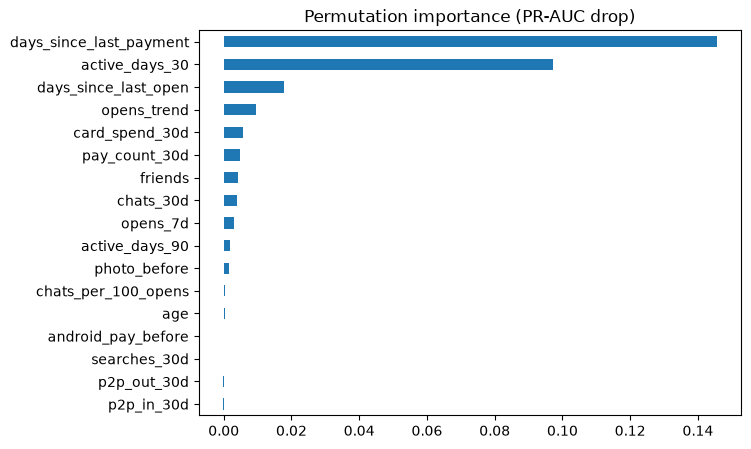

In [19]:
pd.Series(results["importance"]).sort_values().plot.barh(figsize=(7, 5), title="Permutation importance (PR-AUC drop)");

## 5. Backtest: is the result stable?

One test window can be lucky. The backtest repeats the split on consecutive 4-week windows going back in time, with the
same gap rule, and skips windows with fewer than 2,000 training rows.

In [20]:
bt = model.backtest(snaps, settings)
display(bt.round(3))
bt.drop(columns=["test_start", "test_end"]).groupby("model").mean(numeric_only=True).round(3)

,test_start,test_end,train_rows,test_rows,churn_rate,model,pr_auc,roc_auc,recall_top_10pct,precision_top_10pct,lift_top_10pct
0,2018-02-26,2018-03-19,7361,90895,0.086,rule_baseline,0.378,0.870,0.464,0.397,4.635
1,2018-02-26,2018-03-19,7361,90895,0.086,logistic,0.393,0.876,0.472,0.405,4.720
2,2018-02-26,2018-03-19,7361,90895,0.086,gradient_boosting,0.346,0.867,0.428,0.367,4.280
3,2018-03-26,2018-04-16,30816,125156,0.092,rule_baseline,0.375,0.863,0.446,0.410,4.463
4,2018-03-26,2018-04-16,30816,125156,0.092,logistic,0.396,0.871,0.456,0.419,4.563
5,2018-03-26,2018-04-16,30816,125156,0.092,gradient_boosting,0.369,0.871,0.437,0.402,4.375


,train_rows,test_rows,churn_rate,pr_auc,roc_auc,recall_top_10pct,precision_top_10pct,lift_top_10pct
model,,,,,,,,
gradient_boosting,19088.5,108025.5,0.089,0.358,0.869,0.433,0.384,4.327
logistic,19088.5,108025.5,0.089,0.395,0.873,0.464,0.412,4.641
rule_baseline,19088.5,108025.5,0.089,0.377,0.866,0.455,0.404,4.549


## What we did, in one paragraph

We defined **active as making a payment**, looked at retention by monthly cohort, and compared engagement at equal tenure
so growth would not distort it. For prediction we stood on every Monday, described each recently active user using only
what happened before (recency, frequency, spend, p2p, app use, support chats, profile) and labelled them as churned if
they made no payment in the next 60 days. We trained on snapshots whose outcome was already known before the test
window, compared a simple recency rule with two models on ranking metrics that match how a retention team works (who is
in the top 10%), checked the result across several test windows, and set the contact threshold from the cost and value
of an offer rather than at 50%.

The full run with plots and the SHAP explanation is `uv run python -m retention.run`, which writes to `reports/`.